# Pair 1: Fake review detection

**COMP8410 Assignment 1. Name: Arnob Deb Student ID: 60841338.**

A large online travel platform needs to find fake reviews. This notebook compares two graph
neural networks on the public YelpChi dataset, and holds all the code for this pair.

Models used in this notebook: 1. FAGCN (Bo et al., 2021) 2. BWGNN (Tang et al., 2022)
Baselines: MLP, GCN, H2GCN and XGB-Graph


How to use it: Keep this notebook in the same folder as the results and data folders,
open it and run every cell from top to bottom. RUN_TRAINING is False, so the notebook loads
the trained models and results saved in results. It needs no GPU and takes a few minutes. Set it
to True to train every model again which takes about an hour on an RTX 4060 Ti and replaces
the files in results. The README explains the setup.

Where the results came from: The final training run was done from an earlier copy of this folder (60841338_Evaluation\pair1_fake_reviews) as the last line of the log shows, and its results folder was copied here unchanged.

In [ ]:
import hashlib
import json
import platform
import random
import time
import urllib.request
import zipfile
from dataclasses import dataclass
from math import comb
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display
from scipy.special import beta as beta_function
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# False loads the saved results. True trains every model again (about an hour on a GPU).
RUN_TRAINING = False

# True runs a short setup check and uses results_quick.
QUICK = False

# A chosen review for the demo
DEMO_REVIEW = None

# The settings used for the final run. The training limit is deliberately high so early
# stopping ends training rather than the limit. Earlier runs capped at 200 and 1,000 rounds
# still reached their limits. Hidden size 32 keeps FAGCN within an 8 GB GPU and every
# neural model uses the same size.
args = SimpleNamespace(
    seeds=3,        
    epochs=2000,    
    patience=100,   
    trees=2000,     # Maximum number of XGB-Graph trees.
    hidden=32,      
    lr=0.005,       
    dropout=0.3,    
    device="auto",  # auto, cuda or cpu.
    quick=QUICK,
)

# Everything is read from and saved to the folder that holds this notebook. VS Code
# provides the notebook's own path, and Jupyter starts in the notebook's folder.
try:
    HERE = Path(__vsc_ipynb_file__).parent
except NameError:
    HERE = Path.cwd()
print(f"Using the files in {HERE}")

RESULTS_DIR = HERE / ("results_quick" if QUICK else "results")

if not RUN_TRAINING and not (RESULTS_DIR / "runs.csv").exists():
    raise FileNotFoundError(
        f"No saved results in {RESULTS_DIR}. Open the notebook from its own folder, "
        "or set RUN_TRAINING = True to train the models again."
    )

Using the files in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair1_fake_reviews


## 1. Data

YelpChi holds about 46,000 hotel and restaurant reviews, with 32 numeric features each, links
between related reviews, and a label saying whether each review is fake. This section:

1. Downloads the dataset and confirms it is the expected file.
2. Loads the features, labels and links.
3. Creates repeatable train, validation and test splits.
4. Builds the "camouflage" test graph, where fake reviews gain extra links to genuine reviews.

Camouflage imitates fraudsters hiding among normal users, which Week 11 describes as
heterophily. It also creates a distribution shift, which Week 12 describes as a non-IID setting.

In [60]:
# Public copy of the dataset, published with the CARE-GNN paper repository.
DATA_URL = "https://raw.githubusercontent.com/YingtongDou/CARE-GNN/master/data/YelpChi.zip" 

EXPECTED_SHA256 = "3a31296b951e6c8158dddb783ff2c62709fa987d106bbe21e59f8e119053cec3" 

def sha256_of(path: Path) -> str:
    """Return the SHA-256 fingerprint of a file, read in small chunks to save memory."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()  

def download_yelpchi(data_dir: Path) -> Path:
    """Download and unpack YelpChi if needed, then return the path of YelpChi.mat."""
    data_dir.mkdir(parents=True, exist_ok=True)
    mat_path = data_dir / "YelpChi.mat"
    if mat_path.exists():
        return mat_path

    zip_path = data_dir / "YelpChi.zip"
    if not zip_path.exists():
        print(f"Downloading YelpChi from {DATA_URL}")
        urllib.request.urlretrieve(DATA_URL, zip_path)

    # Stop immediately if the download is not the file this evaluation was built on.
    actual = sha256_of(zip_path)
    if actual != EXPECTED_SHA256:
        raise RuntimeError(f"Unexpected dataset file. SHA-256 was {actual}.")

    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(data_dir)
    return mat_path

In [61]:
@dataclass
class ReviewData:
    """Everything the experiments need, kept together in one object."""

    features: np.ndarray  # One row of numeric features per review.
    labels: np.ndarray  # 1 = fake review, 0 = genuine review.
    adjacency: sp.csr_matrix  # Which reviews are linked to which.
    reviewer_review_count: np.ndarray  # Reviews by the same user, used for fairness.

def clean_adjacency(matrix: sp.spmatrix) -> sp.csr_matrix: 
    matrix = sp.csr_matrix(matrix, dtype=np.float32)
    matrix = matrix.maximum(matrix.T)  # A link in either direction becomes two-way.
    matrix.setdiag(0)  # A review should not count as its own neighbour.
    matrix.eliminate_zeros()
    matrix.data[:] = 1.0  # Keep only whether a link exists, not how strong it is.
    return matrix.tocsr()

def load_yelpchi(data_dir: Path) -> ReviewData:
    """Load YelpChi and standardise its features."""
    mat = sio.loadmat(download_yelpchi(data_dir))

    features = np.asarray(mat["features"].todense(), dtype=np.float32)
    labels = np.asarray(mat["label"]).ravel().astype(np.int64)

    # "homo" merges all three YelpChi relation types into one graph.
    adjacency = clean_adjacency(mat["homo"])

    # In "net_rur", two reviews are linked when the same user wrote them. A review's
    # number of R-U-R links plus one is therefore that user's total review count.
    same_user = clean_adjacency(mat["net_rur"])
    reviewer_review_count = np.asarray(same_user.sum(axis=1)).ravel().astype(np.int64) + 1

    # Features have different scales, so give each one mean 0 and standard deviation 1.
    # This uses descriptive statistics only, and no labels.
    mean = features.mean(axis=0, keepdims=True)
    std = features.std(axis=0, keepdims=True)
    std[std == 0] = 1.0
    features = (features - mean) / std

    return ReviewData(features, labels, adjacency, reviewer_review_count)

In [62]:
def make_split(labels: np.ndarray, seed: int) -> dict[str, np.ndarray]:
    """
    Create a stratified 40/20/40 split of train, validation and test reviews.

    Stratified means each part keeps the same share of fake reviews. The seed makes
    the split repeatable, and each seed gives a different split.
    """ 
    indices = np.arange(len(labels))
    train, rest = train_test_split(
        indices, train_size=0.4, stratify=labels, random_state=seed
    )
    # The remaining 60% is divided so that 20% of all data is validation.
    val, test = train_test_split(
        rest, train_size=1 / 3, stratify=labels[rest], random_state=seed
    )
    return {"train": train, "val": val, "test": test}

In [63]:
def add_camouflage_edges(
    adjacency: sp.csr_matrix,
    labels: np.ndarray,
    test_idx: np.ndarray,
    links_per_fake: int,
    seed: int,
) -> sp.csr_matrix:
    """
    Return a copy of the graph where each fake test review gains new genuine neighbours.

    The test imitates fraudsters who connect to normal reviews to look trustworthy.
    The models are not retrained, so this measures how they cope with a changed
    graph after deployment. links_per_fake is how many new links each fake review gets.
    """

    if links_per_fake == 0:
        return adjacency

    rng = np.random.default_rng(seed)
    fake_test = test_idx[labels[test_idx] == 1]
    genuine = np.flatnonzero(labels == 0)

    # Each fake test review is repeated once for every new link it receives.
    sources = np.repeat(fake_test, links_per_fake)
    targets = rng.choice(genuine, size=len(sources), replace=True)

    extra = sp.csr_matrix(
        (np.ones(len(sources), dtype=np.float32), (sources, targets)),
        shape=adjacency.shape,
    )
    return clean_adjacency(adjacency + extra)

In [64]:
class GraphTensors:
    """Stores a graph as PyTorch tensors, ready for the models in models.py."""

    def __init__(self, adjacency: sp.csr_matrix, device: torch.device):
        coo = adjacency.tocoo()
        self.num_nodes = adjacency.shape[0]

        # src[k] -> dst[k] is one directed link. An undirected link appears twice.
        self.src = torch.as_tensor(coo.row, dtype=torch.long, device=device)
        self.dst = torch.as_tensor(coo.col, dtype=torch.long, device=device)

        # Degree is the number of neighbours. clamp(min=1) avoids dividing by zero
        # for isolated reviews with no links.
        degree = np.asarray(adjacency.sum(axis=1)).ravel().astype(np.float32)
        self.degree = torch.as_tensor(degree, device=device).clamp(min=1.0)

        # 1 / sqrt(d_i * d_j) is the symmetric normalisation from Week 11.
        self.edge_norm = 1.0 / torch.sqrt(self.degree[self.src] * self.degree[self.dst])

        # Weight of the two-step path from each review back to itself. H2GCN removes
        # this, because the Week 11 slides exclude a node from its own 2-hop group.
        self.return_weight = torch.zeros(self.num_nodes, device=device).index_add(0, self.src, self.edge_norm**2)

        # Sparse matrix D^(-1/2) A D^(-1/2), used by GCN, H2GCN and BWGNN.
        self.norm_adj = torch.sparse_coo_tensor(
            torch.stack([self.src, self.dst]),
            self.edge_norm,
            size=(self.num_nodes, self.num_nodes),
            device=device,
            check_invariants=False,  # The indices above are already valid.
        ).coalesce()

## 2. Scoring

Week 8 calls this a close-ended task, because each review is either fake or genuine, so the
scores can be calculated automatically. Only about 1 in 7 reviews is fake, so plain accuracy
would mislead. These metrics are designed for that imbalance.

- **Technical scores:** AUROC, AUPRC, Rec@K and F1-macro.
- **Business scores:** fake reviews caught per 1,000 checked, and false alarms per 1,000 genuine reviews.
- **Fairness:** results for new, moderately active and very active reviewers.

In [65]:
def best_threshold(y_true: np.ndarray, scores: np.ndarray) -> float:
    """
    Choose the score cut-off with the best F1-macro on the validation set.

    Using validation data avoids tuning on the test set, which would inflate results.
    """
    candidates = np.unique(np.quantile(scores, np.linspace(0.01, 0.99, 99)))
    f1_values = [
        f1_score(y_true, scores >= threshold, average="macro", zero_division=0)
        for threshold in candidates
    ]
    return float(candidates[int(np.argmax(f1_values))])


def recall_at_k(y_true: np.ndarray, scores: np.ndarray) -> float:
    """
    Rec@K: check as many top-scored reviews as there are fake reviews (K), then
    report the share of fake reviews found. GADBench uses this metric.
    """
    k = int(y_true.sum())
    top = np.argsort(-scores)[:k]
    return float(y_true[top].sum() / k)


def technical_metrics(y_true: np.ndarray, scores: np.ndarray, threshold: float) -> dict[str, float]:
    """Return the technical scores for one model on one set of reviews."""
    predicted = scores >= threshold
    return {
        "auroc": roc_auc_score(y_true, scores),
        "auprc": average_precision_score(y_true, scores),
        "rec_at_k": recall_at_k(y_true, scores),
        "f1_macro": f1_score(y_true, predicted, average="macro", zero_division=0),
    }

In [66]:
def business_metrics(y_true: np.ndarray, scores: np.ndarray, threshold: float, batch: int = 1000) -> dict[str, float]:
    """
    Translate the model's output into moderation-team terms.

    caught_per_1000: a team checks the 1,000 most suspicious reviews. How many are fake?
    false_alarms_per_1000_genuine: of every 1,000 genuine reviews, how many are flagged?
    """
    top = np.argsort(-scores)[:batch]
    predicted = scores >= threshold
    genuine = y_true == 0
    return {
        "caught_per_1000": float(y_true[top].mean() * 1000),
        "false_alarms_per_1000_genuine": float(predicted[genuine].mean() * 1000),
    } 

In [67]:
def activity_group(review_counts: np.ndarray) -> np.ndarray:
    """
    Group reviews by how active their author is, for the fairness check.

    New reviewers have little history, so a good model should not treat them much
    more harshly than established reviewers.
    """
    groups = np.full(len(review_counts), "6 or more reviews", dtype=object)
    groups[review_counts <= 5] = "2 to 5 reviews"
    groups[review_counts == 1] = "1 review"
    return groups

def fairness_by_group(y_true: np.ndarray, scores: np.ndarray, threshold: float, groups: np.ndarray) -> list[dict]:
    """Report how well the model does in each reviewer activity group."""
    rows = []
    predicted = scores >= threshold
    for group in sorted(set(groups)):
        mask = groups == group
        fake = mask & (y_true == 1)
        genuine = mask & (y_true == 0)
        rows.append(
            {
                "group": group,
                "reviews": int(mask.sum()),
                # A small count makes this group's recall unreliable, so report it.
                "fake_reviews": int(fake.sum()),
                "fake_share": float(y_true[mask].mean()),
                # Recall: share of this group's fake reviews that were caught.
                "recall": float(predicted[fake].mean()) if fake.any() else np.nan,
                # False-positive rate: share of this group's genuine reviews flagged.
                "false_positive_rate": float(predicted[genuine].mean()) if genuine.any() else np.nan,
            }
        )
    return rows

## 3. Models

Every model takes the same inputs and returns two scores per review, one for "genuine" and one
for "fake". This keeps the comparison fair.

### Baselines: MLP and GCN

MLP ignores the links altogether. GCN is a low-pass model that averages a review with its neighbours.

In [68]:
class MLP(nn.Module):
    """Baseline that treats each review independently and ignores the graph."""

    def __init__(self, in_dim: int, hidden: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 2),
        )

    def forward(self, x: torch.Tensor, graph: GraphTensors) -> torch.Tensor:
        return self.net(x)


class GCN(nn.Module):
    """
    Baseline low-pass graph model.

    Each layer averages a review with its neighbours. Week 11 explains that this
    helps when linked items are similar and can hide fake reviews when they are not.
    """

    def __init__(self, in_dim: int, hidden: int, dropout: float):
        super().__init__()
        self.layer1 = nn.Linear(in_dim, hidden)
        self.layer2 = nn.Linear(hidden, 2)
        self.dropout = dropout

    @staticmethod
    def propagate(h: torch.Tensor, graph: GraphTensors) -> torch.Tensor:
        # Add the node's own features, which approximates the A + I self-loop in GCN.
        return h + torch.sparse.mm(graph.norm_adj, h)

    def forward(self, x: torch.Tensor, graph: GraphTensors) -> torch.Tensor:
        h = F.relu(self.layer1(self.propagate(x, graph)))
        h = F.dropout(h, self.dropout, self.training)
        return self.layer2(self.propagate(h, graph))

### Baseline: H2GCN

H2GCN is the other heterophily model from Week 11. It keeps a review's own features apart from
those of its neighbours, and it also looks two steps away.

In [69]:
class H2GCN(nn.Module):
    """
    H2GCN, following the three design ideas on the Week 11 slides.

    1. Ego and neighbour separation: a review's own features are kept apart from its
       neighbours' features, so a fake review isn't blended into its genuine neighbours.
    2. Higher-order neighbourhoods: each round also looks two steps away, because a
       review's 2-hop neighbours can be more alike than its direct neighbours.
    3. Combining rounds: the final decision sees the results of every round.

    One change from the paper: it builds a separate list of strict 2-hop neighbours.
    YelpChi has about 1.7 billion two-step paths, which would need roughly 34 GB to
    store. This code applies the 1-hop matrix twice, which reaches the same reviews
    using very little memory, then removes paths that return to the starting review.
    Direct neighbours that are also two steps away still count, so this approximates
    the strict 2-hop set.
    """

    def __init__(self, in_dim: int, hidden: int, dropout: float, rounds: int = 2):
        super().__init__()
        self.embed = nn.Linear(in_dim, hidden)
        self.rounds = rounds
        self.dropout = dropout
        # Each round doubles the width, because it joins the 1-hop and 2-hop results.
        # With 2 rounds, the joined result has 1 + 2 + 4 = 7 times the hidden size.
        total_width = hidden * (2 ** (rounds + 1) - 1)
        self.classify = nn.Linear(total_width, 2)

    def forward(self, x: torch.Tensor, graph: GraphTensors) -> torch.Tensor:
        # Round 0 holds the review's own features only (idea 1).
        h = F.relu(self.embed(x))
        h = F.dropout(h, self.dropout, self.training)
        all_rounds = [h]

        for _ in range(self.rounds):
            # The norm_adj matrix has no self-links, so own features aren't mixed in.
            one_hop = torch.sparse.mm(graph.norm_adj, h)
            two_hop = torch.sparse.mm(graph.norm_adj, one_hop)  # Idea 2.
            two_hop = two_hop - graph.return_weight.unsqueeze(1) * h  # Keeps idea 1.
            h = torch.cat([one_hop, two_hop], dim=1)
            all_rounds.append(h)

        # Idea 3: the classifier sees every round, not only the last one.
        combined = torch.cat(all_rounds, dim=1)
        combined = F.dropout(combined, self.dropout, self.training)
        return self.classify(combined)

### Platform A: FAGCN

FAGCN learns whether to add or subtract each neighbour, so it can handle links between both
similar and dissimilar reviews.

In [70]:
class FAGCNLayer(nn.Module):
    """
    One FAGCN layer, following the equations on the Week 11 slides.

    alpha_ij = tanh(g_left * h_i + g_right * h_j)
    new h_i  = epsilon * h0_i + sum over j of alpha_ij / sqrt(d_i * d_j) * h_j

    alpha can be positive or negative. A positive value adds a neighbour's signal
    (low-frequency) and a negative value subtracts it (high-frequency). The model
    learns which to do for each link.
    """

    def __init__(self, hidden: int, epsilon: float, dropout: float):
        super().__init__()
        # Splitting g into two parts gives the same result as g.T * [h_i || h_j].
        self.g_left = nn.Linear(hidden, 1, bias=False)
        self.g_right = nn.Linear(hidden, 1, bias=False)
        self.epsilon = epsilon
        self.dropout = dropout

    def forward(self, h: torch.Tensor, h0: torch.Tensor, graph: GraphTensors) -> torch.Tensor:
        # Compute one number per node first, because this uses far less memory than
        # building a large concatenated vector for every link.
        left = self.g_left(h).squeeze(-1)
        right = self.g_right(h).squeeze(-1)

        # dst plays the role of node i, which receives a message from src, node j.
        alpha = torch.tanh(left[graph.dst] + right[graph.src])
        alpha = F.dropout(alpha, self.dropout, self.training)

        # Weighted message from each neighbour.
        messages = (alpha * graph.edge_norm).unsqueeze(-1) * h[graph.src]

        # Add up the messages arriving at each review.
        received = torch.zeros_like(h).index_add(0, graph.dst, messages)

        # epsilon * h0 keeps the review's own features, so they are never lost.
        return self.epsilon * h0 + received


class FAGCN(nn.Module):
    """Platform A model: learns whether to add or subtract each neighbour."""

    def __init__(self, in_dim: int, hidden: int, dropout: float, epsilon: float = 0.3, layers: int = 2):
        super().__init__()
        self.embed = nn.Linear(in_dim, hidden)
        self.layers = nn.ModuleList(
            [FAGCNLayer(hidden, epsilon, dropout) for _ in range(layers)]
        )
        self.classify = nn.Linear(hidden, 2)
        self.dropout = dropout

    def forward(self, x: torch.Tensor, graph: GraphTensors) -> torch.Tensor:
        # Step 1: embed each review's features.
        h0 = F.dropout(F.relu(self.embed(x)), self.dropout, self.training)

        # Step 2: signed aggregation, repeated for each layer.
        h = h0
        for layer in self.layers:
            h = layer(h, h0, graph)

        # Step 3: classify each review.
        return self.classify(h)

### Platform B: BWGNN

BWGNN passes signals through band-pass filters, so it keeps low, middle and high graph
frequencies side by side. It is based on the idea that anomalies shift towards higher frequencies.

In [71]:
def beta_wavelet_coefficients(order: int) -> list[np.ndarray]:
    """
    Work out the polynomial coefficients of the beta wavelet filters.

    BWGNN builds order + 1 filters. Filter i has this shape over graph frequency L:
        (L / 2)^i * (1 - L / 2)^(order - i) / Beta(i + 1, order - i + 1)

    Expanding the shape into powers of L lets the model apply each filter by
    repeatedly multiplying with the Laplacian, with no eigen-decomposition.
    """
    filters = []
    for i in range(order + 1):
        coefficients = np.zeros(order + 1)
        remaining = order - i
        # Binomial expansion of (1 - L/2)^remaining, then multiply by (L/2)^i.
        for k in range(remaining + 1):
            power = i + k
            coefficients[power] = comb(remaining, k) * (-1) ** k * 0.5 ** power
        filters.append(coefficients / beta_function(i + 1, remaining + 1))
    return filters

class BWGNN(nn.Module):
    """
    Platform B model: Beta Wavelet GNN.

    It passes signals through several band-pass filters, keeping low, middle and
    high graph frequencies side by side. This suits fake reviews, whose signal may
    not be smooth across links. Filter outputs are concatenated, not averaged.
    """

    def __init__(self, in_dim: int, hidden: int, dropout: float, order: int = 2):
        super().__init__()
        self.embed = nn.Linear(in_dim, hidden)
        filters = beta_wavelet_coefficients(order)
        # A buffer moves with the model to the GPU, but it is not a learned parameter.
        self.register_buffer("theta", torch.tensor(np.array(filters), dtype=torch.float32))
        self.head = nn.Sequential(
            nn.Linear(hidden * (order + 1), hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 2),
        )
        self.dropout = dropout
        self.order = order

    @staticmethod
    def laplacian(h: torch.Tensor, graph: GraphTensors) -> torch.Tensor:
        # Symmetric normalised Laplacian: L h = h - D^(-1/2) A D^(-1/2) h.
        return h - torch.sparse.mm(graph.norm_adj, h)

    def forward(self, x: torch.Tensor, graph: GraphTensors) -> torch.Tensor:
        h = F.dropout(F.relu(self.embed(x)), self.dropout, self.training)

        # powers holds [h, L h, L^2 h, ...], computed once and reused by every filter.
        powers = [h]
        for _ in range(self.order):
            powers.append(self.laplacian(powers[-1], graph))
        stacked = torch.stack(powers, dim=0)  # Shape: powers, reviews, hidden size.

        # Each filter is a weighted sum of the powers of L.
        filtered = torch.einsum("fp,prh->frh", self.theta, stacked)

        # Keep every frequency band by joining the filter outputs.
        joined = filtered.permute(1, 0, 2).reshape(x.shape[0], -1)
        return self.head(joined)

In [72]:
def build_model(name: str, in_dim: int, hidden: int, dropout: float) -> nn.Module:
    """Create a model from its name, so experiments can loop over the model list."""
    models = {"MLP": MLP, "GCN": GCN, "FAGCN": FAGCN, "H2GCN": H2GCN, "BWGNN": BWGNN}
    return models[name](in_dim, hidden, dropout)

## 4. Training and testing

Early stopping and the decision threshold both use validation data only, so the test set stays
unseen. XGB-Graph is handled separately, because it isn't trained by gradient descent.

In [73]:
# Neural models. XGB-Graph is handled separately, because it is not trained by
# gradient descent.
NEURAL_MODELS = ["MLP", "GCN", "FAGCN", "H2GCN", "BWGNN"]

# Number of new genuine neighbours given to each fake test review.
CAMOUFLAGE_LEVELS = [0, 25, 100, 400]

def set_seed(seed: int) -> None:
    """Fix random number generators so that a run can be repeated."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def fake_probability(model: torch.nn.Module, x: torch.Tensor, graph: GraphTensors) -> np.ndarray:
    """Return each review's predicted probability of being fake."""
    model.eval()
    return F.softmax(model(x, graph), dim=1)[:, 1].cpu().numpy()

In [74]:
def train_neural_model(name, args, data, x, labels, graph, split, device):
    """Train one neural model and return the version with the best validation score."""
    model = build_model(name, x.shape[1], args.hidden, args.dropout).to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=args.lr, weight_decay=5e-5)

    # Fake reviews are the minority, so errors on them receive more weight.
    train_idx = torch.as_tensor(split["train"], device=device)
    fake_share = float(labels[train_idx].float().mean())
    class_weight = torch.tensor([1.0, (1 - fake_share) / fake_share], device=device)

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    best_score, best_state, best_epoch, rounds_without_gain = -1.0, None, 0, 0
    history = []  # Validation score per round, which shows whether training settled.
    started = time.perf_counter()

    for epoch in range(1, args.epochs + 1):
        # One full training step over all training reviews.
        model.train()
        optimiser.zero_grad()
        logits = model(x, graph)
        loss = F.cross_entropy(logits[train_idx], labels[train_idx], weight=class_weight)
        loss.backward()
        optimiser.step()

        # Check progress on validation data only. The test set stays unseen.
        scores = fake_probability(model, x, graph)
        val = split["val"]
        current = technical_metrics(data.labels[val], scores[val], 0.5)["auprc"]
        history.append({"epoch": epoch, "val_auprc": current})
        if current > best_score:
            best_score = current
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_epoch = epoch
            rounds_without_gain = 0
        else:
            rounds_without_gain += 1

        if epoch == 1 or epoch % 50 == 0:
            print(f"    epoch {epoch:4d}  loss {loss.item():.4f}  val AUPRC {current:.4f}")

        # Early stopping saves time and reduces overfitting.
        if rounds_without_gain >= args.patience:
            print(f"    stopped early at epoch {epoch}")
            break

    model.load_state_dict(best_state)
    run_info = {
        "train_seconds": time.perf_counter() - started,
        "epochs_run": epoch,
        "best_epoch": best_epoch,  # The round whose saved model is used for testing.
        "peak_gpu_gb": torch.cuda.max_memory_allocated(device) / 1024**3 if device.type == "cuda" else np.nan,
        "parameters": sum(p.numel() for p in model.parameters()),
    }
    return model, run_info, history

In [75]:
def neighbour_features(features: np.ndarray, adjacency: sp.csr_matrix) -> np.ndarray:
    """
    Build the XGB-Graph inputs: own features plus 1-hop and 2-hop neighbour averages.

    GADBench found that this simple recipe can beat specialised GNNs, which makes it
    a demanding baseline for the two graph models.
    """
    degree = np.asarray(adjacency.sum(axis=1)).ravel()
    inverse_degree = sp.diags(1.0 / np.maximum(degree, 1.0))
    mean_operator = inverse_degree @ adjacency
    one_hop = mean_operator @ features
    two_hop = mean_operator @ one_hop
    return np.hstack([features, one_hop, two_hop]).astype(np.float32)


def train_xgb_graph(graph_features, labels, split, seed, use_gpu, max_trees):
    """Train the XGB-Graph baseline."""
    train, val = split["train"], split["val"]
    fake_share = labels[train].mean()
    model = XGBClassifier(
        n_estimators=max_trees,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=(1 - fake_share) / fake_share,  # Handles the class imbalance.
        tree_method="hist",
        device="cuda" if use_gpu else "cpu",
        early_stopping_rounds=50,
        eval_metric="aucpr",
        random_state=seed,
    )
    started = time.perf_counter()
    model.fit(graph_features[train], labels[train], eval_set=[(graph_features[val], labels[val])], verbose=False)
    info = {
        "train_seconds": time.perf_counter() - started,
        "epochs_run": model.get_booster().num_boosted_rounds(),  # Trees actually built.
        "best_epoch": model.best_iteration + 1,  # Trees kept for testing.
        "peak_gpu_gb": np.nan,
        "parameters": np.nan,
    }
    return model, info


def inference_ms_per_1000(predict, num_reviews: int) -> float:
    """Time one full prediction pass, in milliseconds per 1,000 reviews."""
    started = time.perf_counter()
    predict()
    return (time.perf_counter() - started) * 1000 / (num_reviews / 1000)

This function runs the whole experiment. For each seed and model, it trains the model, chooses
a threshold on validation data, then runs the performance, fairness and camouflage tests. It
saves the results after every model, so a crash doesn't lose earlier work.

In [76]:
def run_full_evaluation(args) -> None:
    """Train every model on the same splits, test them, and save all the results."""

    # A quick check trains briefly on one split, so it only proves the code runs.
    if args.quick:
        args.seeds, args.epochs, args.patience, args.hidden, args.trees = 1, 3, 3, 16, 50
    results_dir = HERE / ("results_quick" if args.quick else "results")
    results_dir.mkdir(exist_ok=True)

    # The first seed's trained models are kept for the video demo in demo.py.
    models_dir = results_dir / "models"
    models_dir.mkdir(exist_ok=True)

    use_gpu = torch.cuda.is_available() and args.device != "cpu"
    device = torch.device("cuda" if use_gpu else "cpu")
    print(f"Running on {torch.cuda.get_device_name(0) if use_gpu else 'CPU'}")

    data = load_yelpchi(HERE / "data")
    groups = activity_group(data.reviewer_review_count)
    x = torch.as_tensor(data.features, device=device)
    labels = torch.as_tensor(data.labels, device=device)
    clean_graph = GraphTensors(data.adjacency, device)

    runs, fairness_rows, camouflage_rows, curve_rows, failure_rows, training_rows = [], [], [], [], [], []
    total_runs = args.seeds * (len(NEURAL_MODELS) + 1)
    finished = 0

    for seed in range(args.seeds):
        split = make_split(data.labels, seed)
        test = split["test"]
        y_test = data.labels[test]
        clean_inputs = neighbour_features(data.features, data.adjacency)

        for name in NEURAL_MODELS + ["XGB-Graph"]:
            print(f"\nSeed {seed}: {name} (run {finished + 1} of {total_runs})")
            set_seed(seed)

            # Each model gets a prediction function, so the tests below are shared.
            if name == "XGB-Graph":
                model, info = train_xgb_graph(clean_inputs, data.labels, split, seed, use_gpu, args.trees)
                if seed == 0:
                    model.save_model(models_dir / "XGB-Graph.json")

                def predict(adjacency):
                    inputs = clean_inputs if adjacency is None else neighbour_features(data.features, adjacency)
                    return model.predict_proba(inputs)[:, 1]
            else:
                model, info, history = train_neural_model(name, args, data, x, labels, clean_graph, split, device)
                training_rows += [{"model": name, "seed": seed, **row} for row in history]
                if seed == 0:
                    torch.save(model.state_dict(), models_dir / f"{name}.pt")

                def predict(adjacency):
                    graph = clean_graph if adjacency is None else GraphTensors(adjacency, device)
                    return fake_probability(model, x, graph)

            # The threshold comes from validation data and stays fixed for all tests.
            scores = predict(None)
            threshold = best_threshold(data.labels[split["val"]], scores[split["val"]])
            info["inference_ms_per_1000"] = inference_ms_per_1000(lambda: predict(None), len(data.labels))

            # Main results on clean test data.
            runs.append(
                {
                    "model": name,
                    "seed": seed,
                    "threshold": threshold,
                    **technical_metrics(y_test, scores[test], threshold),
                    **business_metrics(y_test, scores[test], threshold),
                    **info,
                }
            )

            # Fairness across reviewer activity groups.
            for row in fairness_by_group(y_test, scores[test], threshold, groups[test]):
                fairness_rows.append({"model": name, "seed": seed, **row})

            # Precision-recall curve for the first seed, for the report chart.
            if seed == 0:
                precision, recall, _ = precision_recall_curve(y_test, scores[test])
                keep = np.linspace(0, len(precision) - 1, 400).astype(int)
                curve_rows += [
                    {"model": name, "precision": p, "recall": r}
                    for p, r in zip(precision[keep], recall[keep])
                ]

                # Save the model's worst mistakes for the gaps and failure analysis.
                order = test[np.argsort(-scores[test])]
                false_alarms = order[data.labels[order] == 0][:20]
                missed = order[data.labels[order] == 1][-20:]
                for kind, ids in [("false alarm", false_alarms), ("missed fake", missed)]:
                    for review_id in ids:
                        failure_rows.append(
                            {
                                "model": name,
                                "type": kind,
                                "review_id": int(review_id),
                                "score": float(scores[review_id]),
                                "reviewer_reviews": int(data.reviewer_review_count[review_id]),
                            }
                        )

            # Camouflage test: same trained model, changed test graph.
            for level in CAMOUFLAGE_LEVELS:
                changed = add_camouflage_edges(data.adjacency, data.labels, test, level, seed)
                level_scores = predict(None if level == 0 else changed)
                camouflage_rows.append(
                    {
                        "model": name,
                        "seed": seed,
                        "links_per_fake": level,
                        **technical_metrics(y_test, level_scores[test], threshold),
                    }
                )

            finished += 1
            # Save after every model, so a crash doesn't lose earlier work.
            pd.DataFrame(runs).to_csv(results_dir / "runs.csv", index=False)
            pd.DataFrame(fairness_rows).to_csv(results_dir / "fairness.csv", index=False)
            pd.DataFrame(camouflage_rows).to_csv(results_dir / "camouflage.csv", index=False)
            pd.DataFrame(curve_rows).to_csv(results_dir / "pr_curves.csv", index=False)
            pd.DataFrame(failure_rows).to_csv(results_dir / "failure_cases.csv", index=False)
            pd.DataFrame(training_rows).to_csv(results_dir / "training_curves.csv", index=False)

    # Mean and standard deviation across seeds, for the report tables.
    numeric = pd.DataFrame(runs).drop(columns=["seed"])
    summary = numeric.groupby("model", sort=False).agg(["mean", "std"]).round(4)
    summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
    summary.to_csv(results_dir / "summary.csv")

    # Record the run settings, which the report and AI use evidence need.
    environment = {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "device": torch.cuda.get_device_name(0) if use_gpu else "CPU",
        "settings": vars(args),
        "fake_share": float(data.labels.mean()),
        "reviews": int(len(data.labels)),
        "links": int(data.adjacency.nnz / 2),
    }
    (results_dir / "environment.json").write_text(json.dumps(environment, indent=2))
    print(f"\nFinished. Results are in {results_dir}")

## 5. Run the evaluation

With `RUN_TRAINING = False`, this cell does nothing and the saved results are used.

In [77]:
if RUN_TRAINING:
    run_full_evaluation(args)
else:
    print(f"Skipping training. Using the saved results in {RESULTS_DIR}")

Running on NVIDIA GeForce RTX 4060 Ti

Seed 0: MLP (run 1 of 18)
    epoch    1  loss 0.7027  val AUPRC 0.1653
    epoch   50  loss 0.5216  val AUPRC 0.5123
    epoch  100  loss 0.4919  val AUPRC 0.5534
    epoch  150  loss 0.4723  val AUPRC 0.5792
    epoch  200  loss 0.4577  val AUPRC 0.5823
    epoch  250  loss 0.4466  val AUPRC 0.5871
    epoch  300  loss 0.4447  val AUPRC 0.5870
    epoch  350  loss 0.4381  val AUPRC 0.5859
    stopped early at epoch 366

Seed 0: GCN (run 2 of 18)
    epoch    1  loss 0.8355  val AUPRC 0.1463
    epoch   50  loss 0.5363  val AUPRC 0.4793
    epoch  100  loss 0.5120  val AUPRC 0.5100
    epoch  150  loss 0.4978  val AUPRC 0.5261
    epoch  200  loss 0.4878  val AUPRC 0.5374
    epoch  250  loss 0.4776  val AUPRC 0.5471
    epoch  300  loss 0.4696  val AUPRC 0.5544
    epoch  350  loss 0.4652  val AUPRC 0.5620
    epoch  400  loss 0.4558  val AUPRC 0.5600
    epoch  450  loss 0.4527  val AUPRC 0.5635
    epoch  500  loss 0.4491  val AUPRC 0.5625
   

d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\60841338_Evaluation\.venv\Lib\site-packages\xgboost\core.py:751: UserWarning: [02:33:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



Seed 1: MLP (run 7 of 18)
    epoch    1  loss 0.6943  val AUPRC 0.2901
    epoch   50  loss 0.5256  val AUPRC 0.4886
    epoch  100  loss 0.4944  val AUPRC 0.5265
    epoch  150  loss 0.4735  val AUPRC 0.5439
    epoch  200  loss 0.4514  val AUPRC 0.5644
    epoch  250  loss 0.4424  val AUPRC 0.5716
    epoch  300  loss 0.4335  val AUPRC 0.5815
    epoch  350  loss 0.4318  val AUPRC 0.5814
    epoch  400  loss 0.4234  val AUPRC 0.5833
    epoch  450  loss 0.4220  val AUPRC 0.5874
    epoch  500  loss 0.4164  val AUPRC 0.5875
    epoch  550  loss 0.4173  val AUPRC 0.5878
    epoch  600  loss 0.4148  val AUPRC 0.5926
    epoch  650  loss 0.4083  val AUPRC 0.5859
    epoch  700  loss 0.4088  val AUPRC 0.5862
    stopped early at epoch 707

Seed 1: GCN (run 8 of 18)
    epoch    1  loss 0.6972  val AUPRC 0.2420
    epoch   50  loss 0.5203  val AUPRC 0.5098
    epoch  100  loss 0.4994  val AUPRC 0.5302
    epoch  150  loss 0.4872  val AUPRC 0.5425
    epoch  200  loss 0.4812  val AUPRC 0.

## 6. Results

### Run settings

This shows the settings and hardware recorded when the results were produced.

In [78]:
environment = json.loads((RESULTS_DIR / "environment.json").read_text())
print(json.dumps(environment, indent=2))

{
  "python": "3.11.9",
  "torch": "2.14.1+cu126",
  "device": "NVIDIA GeForce RTX 4060 Ti",
  "settings": {
    "seeds": 3,
    "epochs": 2000,
    "patience": 100,
    "trees": 2000,
    "hidden": 32,
    "lr": 0.005,
    "dropout": 0.3,
    "device": "auto",
    "quick": false
  },
  "fake_share": 0.14529747138442792,
  "reviews": 45954,
  "links": 3846979
}


### Technical and business performance

Each value is the mean across seeds. `epochs_run` shows whether a model reached its limit.

In [79]:
runs = pd.read_csv(RESULTS_DIR / "runs.csv")
columns = [
    "auroc", "auprc", "rec_at_k", "f1_macro", "caught_per_1000", "false_alarms_per_1000_genuine",
    "train_seconds", "epochs_run", "peak_gpu_gb", "inference_ms_per_1000",
]
display(runs.groupby("model", sort=False)[columns].mean().round(3))

# The spread across seeds shows how far the main score moved between repeats.
display(runs.groupby("model", sort=False)["auprc"].std().round(3).to_frame("auprc_std"))

,auroc,auprc,rec_at_k,f1_macro,caught_per_1000,false_alarms_per_1000_genuine,train_seconds,epochs_run,peak_gpu_gb,inference_ms_per_1000
model,,,,,,,,,,
MLP,0.856,0.573,0.546,0.733,753.000,74.109,9.022,550.667,0.342,0.058
GCN,0.862,0.583,0.549,0.736,751.000,74.916,53.560,875.333,0.800,0.229
FAGCN,0.879,0.644,0.588,0.756,817.000,64.074,235.790,1111.667,6.000,1.006
H2GCN,0.862,0.589,0.552,0.738,764.333,77.695,187.853,1165.333,0.860,0.234
BWGNN,0.895,0.685,0.623,0.778,854.333,60.255,59.391,704.333,0.816,0.110
XGB-Graph,0.963,0.874,0.787,0.876,982.667,32.652,57.647,1022.667,NaN,0.921


,auprc_std
model,
MLP,0.018
GCN,0.011
FAGCN,0.016
H2GCN,0.013
BWGNN,0.004
XGB-Graph,0.001


*** 
Fairness and Graph

In [80]:
fairness = pd.read_csv(RESULTS_DIR / "fairness.csv")
display(fairness.groupby(["model", "group"], sort=False)[["fake_reviews", "recall", "false_positive_rate"]].mean().round(3))

fake_reviews  recall  false_positive_rate
model     group                                                       
MLP       1 review                 2197.0   0.542                0.075
          2 to 5 reviews            453.0   0.505                0.074
          6 or more reviews          21.0   0.394                0.072
GCN       1 review                 2197.0   0.564                0.086
          2 to 5 reviews            453.0   0.459                0.070
          6 or more reviews          21.0   0.362                0.060
FAGCN     1 review                 2197.0   0.585                0.070
          2 to 5 reviews            453.0   0.471                0.062
          6 or more reviews          21.0   0.424                0.053
H2GCN     1 review                 2197.0   0.577                0.085
          2 to 5 reviews            453.0   0.457                0.075
          6 or more reviews          21.0   0.407                0.067
BWGNN     1 review                 2197.0   0.630                0.066
          2 to 5 reviews            453.0   0.509                0.061
          6 or more reviews          21.0   0.472                0.046
XGB-Graph 1 review                 2197.0   0.809                0.034
          2 to 5 reviews            453.0   0.616                0.035
          6 or more reviews          21.0   0.506                0.024

### Gaps

These reviews appear in the worst-mistakes list of every model, so they are the cases that all
six models get wrong.

In [81]:
failures = pd.read_csv(RESULTS_DIR / "failure_cases.csv")
model_counts = failures.groupby(["review_id", "type"])["model"].nunique().reset_index()
display(model_counts[model_counts["model"] == failures["model"].nunique()])

,review_id,type,model
102,38450,missed fake,6


## 7. Charts

The charts read the saved CSV files only, so every plotted number traces to a result file.
They are saved in `results/figures`.

In [82]:
# Each model keeps the same colour in every chart, so readers can follow it.
COLOURS = {
    "FAGCN": "#2a78d6",
    "BWGNN": "#eb6834",
    "H2GCN": "#7a5fc9",
    "XGB-Graph": "#1baf7a",
    "GCN": "#eda100",
    "MLP": "#e87ba4",
}


MODEL_ORDER = list(COLOURS)


TEXT = "#0b0b0b"


MUTED = "#52514e"


GRID = "#e4e3df"


plt.rcParams.update(
    {
        "font.size": 10,
        "text.color": TEXT,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
    }
)


def present(models) -> list[str]:
    """Keep the fixed model order, using only the models found in the results."""
    return [model for model in MODEL_ORDER if model in set(models)]

In [83]:
def chart_performance(results: Path, out: Path) -> None:
    """Show mean test scores, with a whisker for variation across seeds."""
    runs = pd.read_csv(results / "runs.csv")
    panels = [
        ("auroc", "AUROC"),
        ("auprc", "AUPRC"),
        ("rec_at_k", "Rec@K"),
        ("f1_macro", "F1-macro"),
    ]
    models = present(runs["model"])
    fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)

    for axis, (column, title) in zip(axes, panels):
        stats = runs.groupby("model")[column].agg(["mean", "std"]).fillna(0)
        for row, model in enumerate(models):
            mean, std = stats.loc[model, "mean"], stats.loc[model, "std"]
            axis.errorbar(mean, row, xerr=std, fmt="o", color=COLOURS[model], markersize=7, capsize=3, linewidth=1.5)
            # A small offset keeps each value clear of its whisker.
            axis.annotate(f"{mean:.3f}", (mean, row), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
        axis.set_title(title, fontsize=10, loc="left", color=TEXT)
        axis.grid(axis="x", color=GRID, linewidth=0.8)
        axis.set_axisbelow(True)
        axis.margins(x=0.25)
        axis.set_ylim(-0.6, len(models) - 0.3)

    axes[0].set_yticks(range(len(models)), models)
    axes[0].invert_yaxis()
    fig.suptitle("Test performance by model, mean across seeds", x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    fig.savefig(out / "fig1_performance.png")
    plt.close(fig)

In [84]:
def chart_precision_recall(results: Path, out: Path) -> None:
    """Show the trade-off between catching fakes and avoiding false alarms."""
    curves = pd.read_csv(results / "pr_curves.csv")
    fig, axis = plt.subplots(figsize=(6, 4))
    for model in present(curves["model"]):
        part = curves[curves["model"] == model]
        axis.plot(part["recall"], part["precision"], color=COLOURS[model], linewidth=2, label=model)
    axis.set_xlabel("Recall: share of fake reviews caught")
    axis.set_ylabel("Precision: share of flags that are correct")
    axis.set_title("Precision and recall on the test set, first seed", loc="left", fontsize=12, fontweight="bold")
    axis.grid(color=GRID, linewidth=0.8)
    axis.legend(frameon=False)
    fig.savefig(out / "fig2_precision_recall.png")
    plt.close(fig)

In [85]:
def chart_fairness(results: Path, out: Path) -> None:
    """Compare recall and false alarms across reviewer activity groups."""
    fairness = pd.read_csv(results / "fairness.csv")
    groups = ["1 review", "2 to 5 reviews", "6 or more reviews"]
    groups = [group for group in groups if group in set(fairness["group"])]
    models = present(fairness["model"])
    means = fairness.groupby(["model", "group"])[["recall", "false_positive_rate"]].mean()

    # Show how many fake reviews sit behind each group's recall. Older result files
    # don't have this column, so calculate it from their review counts.
    if "fake_reviews" not in fairness:
        fairness["fake_reviews"] = fairness["reviews"] * fairness["fake_share"]
    fake_counts = fairness.groupby("group")["fake_reviews"].mean()
    group_labels = [f"{group}\n(about {fake_counts[group]:,.0f} fakes)" for group in groups]

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
    panels = [("recall", "Recall"), ("false_positive_rate", "False positive rate")]
    spacing = 0.8 / max(len(models), 1)

    for axis, (column, title) in zip(axes, panels):
        for index, model in enumerate(models):
            # Each model sits at a small offset inside its group's row.
            positions = [row - 0.4 + spacing * (index + 0.5) for row in range(len(groups))]
            values = [means.loc[(model, group), column] for group in groups]
            axis.scatter(values, positions, color=COLOURS[model], s=45, label=model, zorder=3)
        axis.set_title(title, loc="left", fontsize=10, color=TEXT)
        axis.grid(axis="x", color=GRID, linewidth=0.8)
        axis.set_axisbelow(True)

    axes[0].set_yticks(range(len(groups)), group_labels)
    axes[0].invert_yaxis()
    axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.suptitle("Results by reviewer activity, mean across seeds", x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    fig.savefig(out / "fig3_fairness.png")
    plt.close(fig)

In [86]:
def chart_camouflage(results: Path, out: Path) -> None:
    """
    Show how detection changes as fake reviews gain links to genuine reviews.

    Each line is the mean, and its band runs from the lowest to the highest seed. A mean
    alone can hide one seed failing badly, which is exactly what this test looks for.
    """
    camouflage = pd.read_csv(results / "camouflage.csv")
    levels = sorted(camouflage["links_per_fake"].unique())
    fake_share = 0.145  # A random ranking scores about this on AUPRC for YelpChi.
    panels = [("auprc", "AUPRC", fake_share), ("auroc", "AUROC", 0.5)]

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
    for axis, (column, title, random_score) in zip(axes, panels):
        stats = camouflage.groupby(["model", "links_per_fake"])[column].agg(["mean", "min", "max"]).reset_index()
        for model in present(stats["model"]):
            part = stats[stats["model"] == model].sort_values("links_per_fake")
            # Evenly spaced positions, because the levels grow by uneven steps.
            positions = range(len(levels))
            axis.fill_between(positions, part["min"], part["max"], color=COLOURS[model], alpha=0.15, linewidth=0)
            axis.plot(positions, part["mean"], color=COLOURS[model], linewidth=2, marker="o", markersize=7, label=model)
        axis.axhline(random_score, color=MUTED, linewidth=1, linestyle="--")
        axis.annotate("Random ranking", (0, random_score), xytext=(0, 3), textcoords="offset points", fontsize=8, color=MUTED)
        axis.set_xticks(range(len(levels)), levels)
        axis.set_xlabel("New genuine links added to each fake test review")
        axis.set_title(title, loc="left", fontsize=10, color=TEXT)
        axis.grid(axis="y", color=GRID, linewidth=0.8)
        axis.set_axisbelow(True)

    axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.suptitle(
        "Detection under camouflage: line is the mean, band is lowest to highest seed",
        x=0.01, ha="left", fontsize=12, fontweight="bold",
    )
    fig.tight_layout()
    fig.savefig(out / "fig4_camouflage.png")
    plt.close(fig)

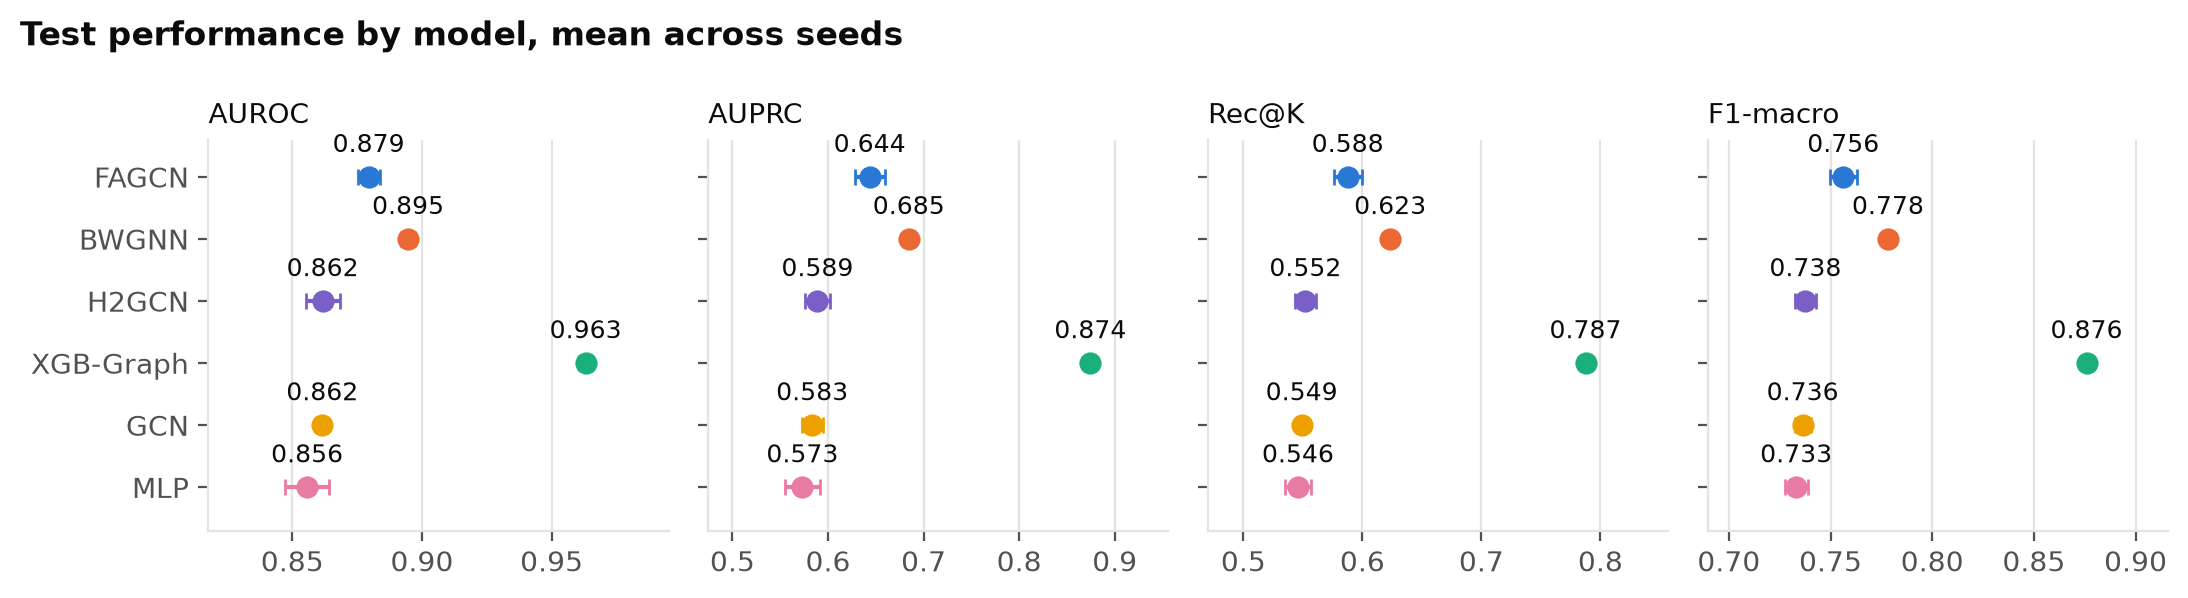

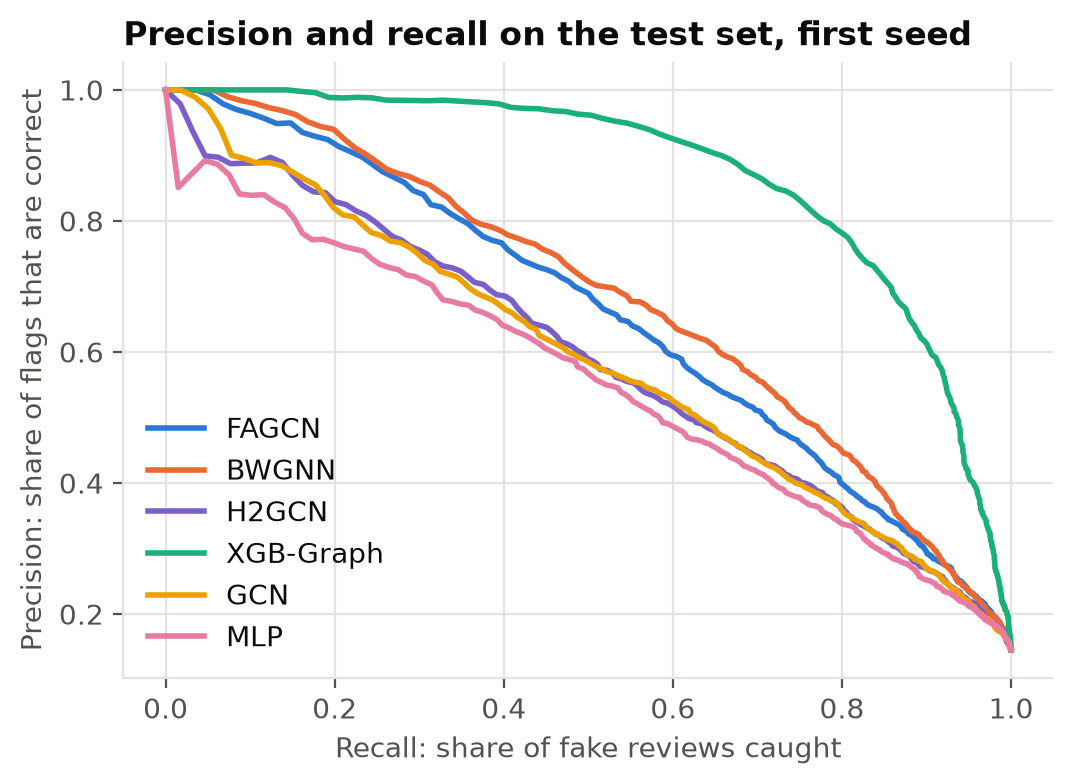

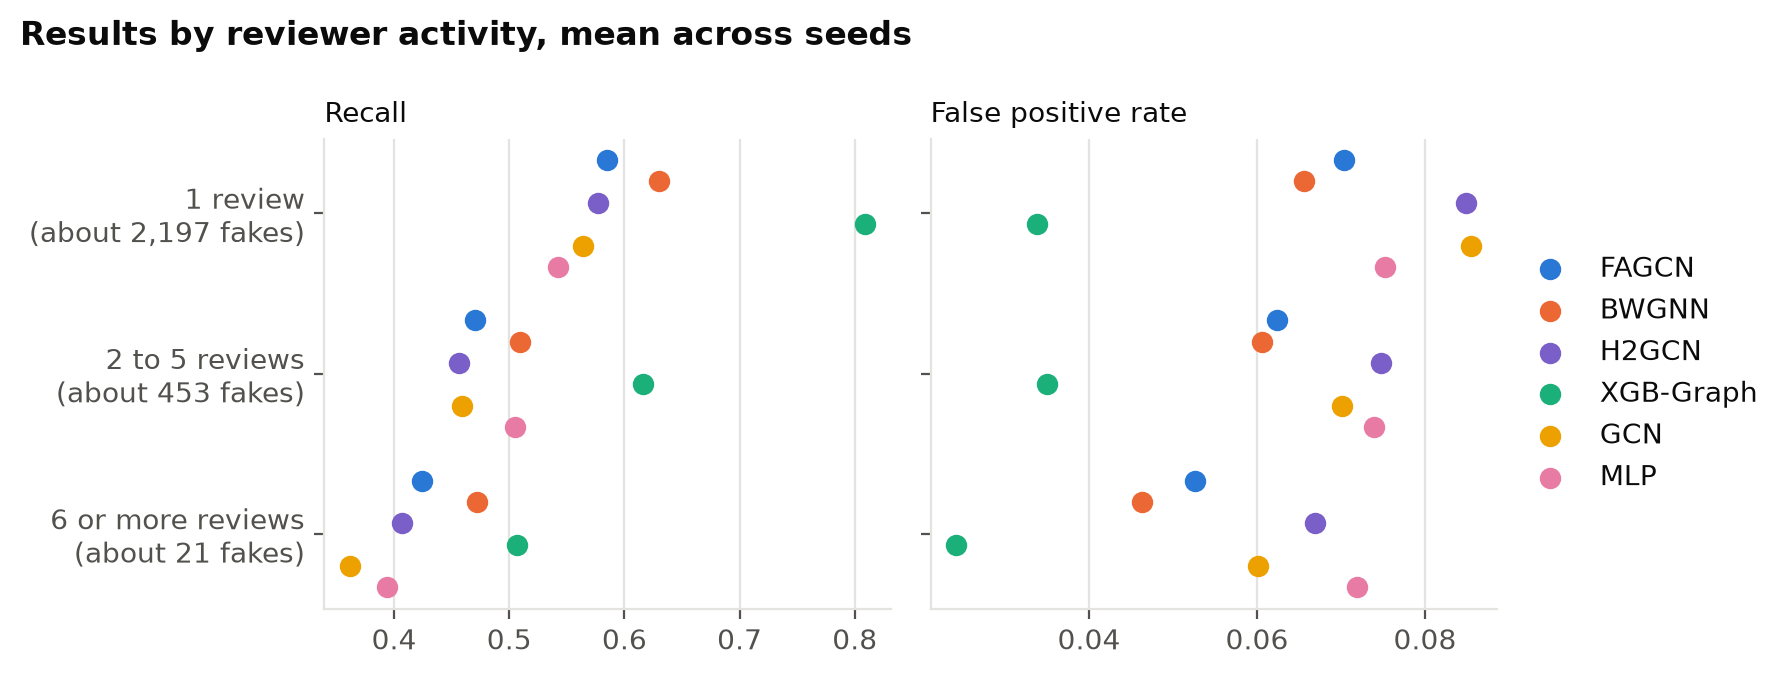

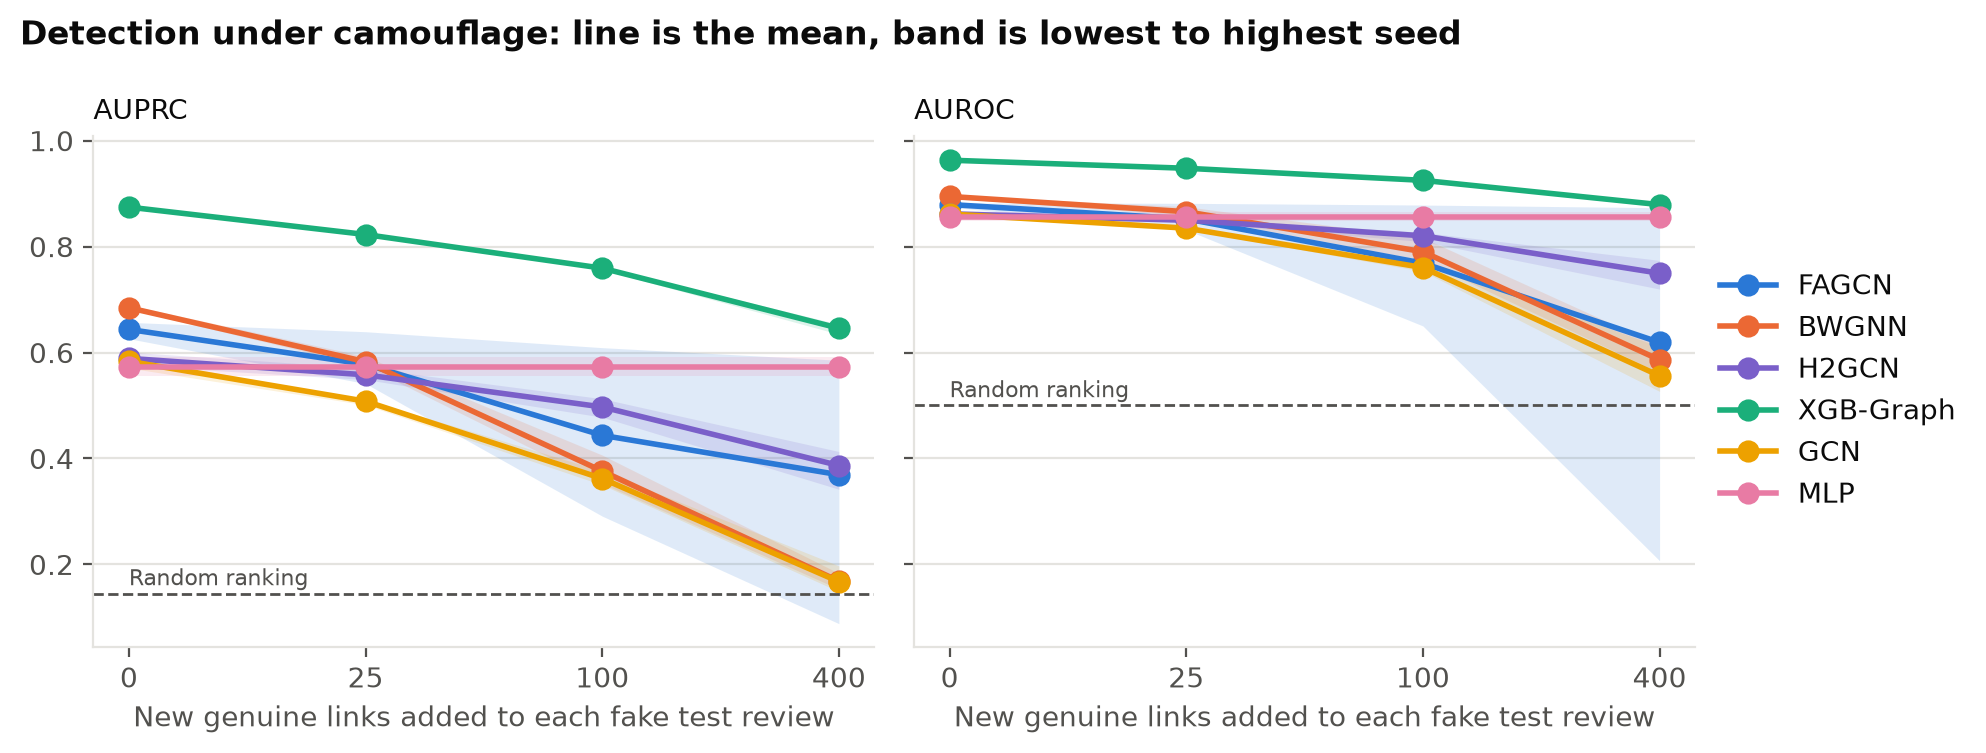

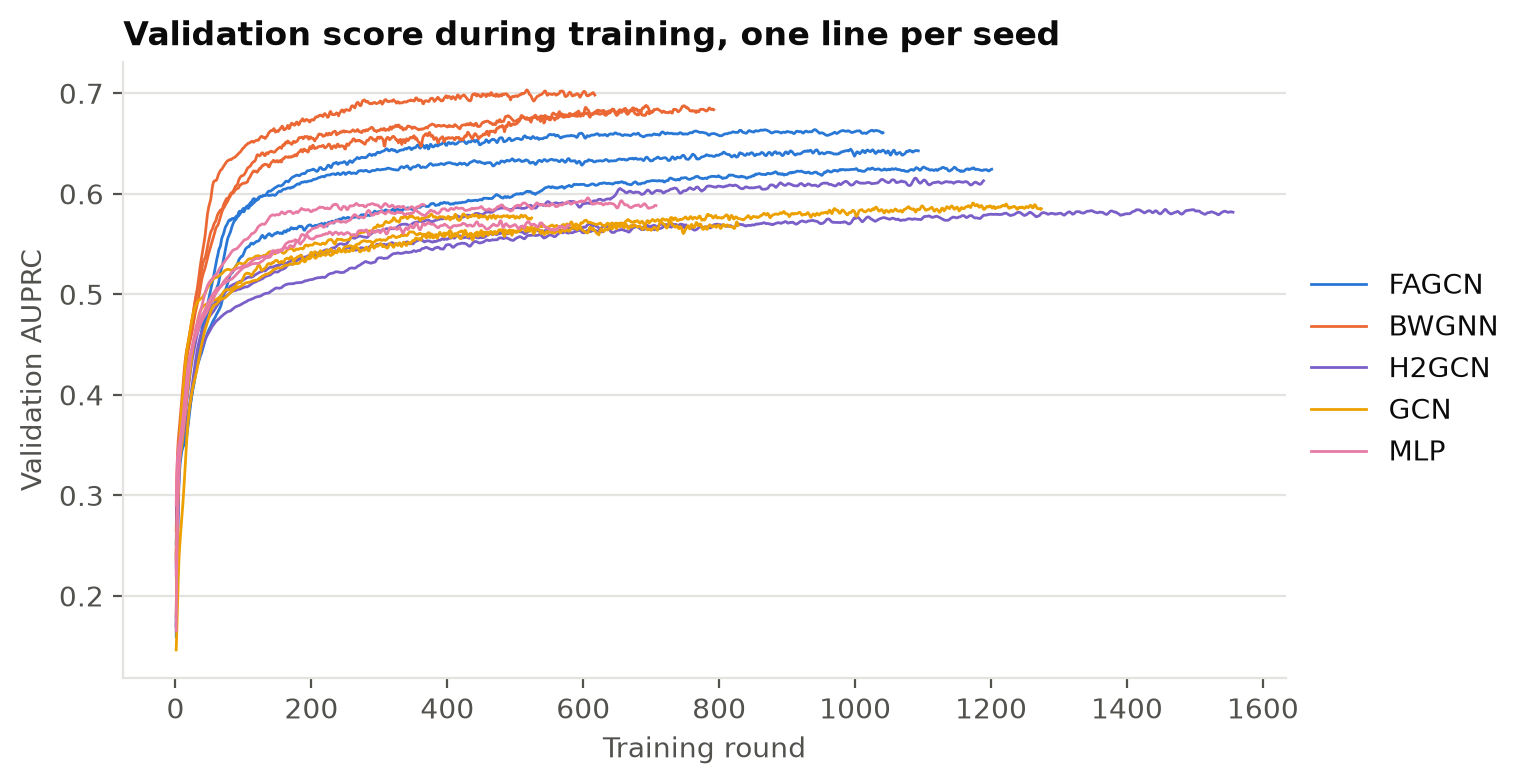

In [87]:
def chart_training(results: Path, out: Path) -> None:
    """Show validation scores per round, as evidence that training had settled."""
    path = results / "training_curves.csv"
    if not path.exists():  # Older result files don't include this data.
        return
    curves = pd.read_csv(path)
    fig, axis = plt.subplots(figsize=(7.5, 4))
    for model in present(curves["model"]):
        part = curves[curves["model"] == model]
        for index, (_, seed_run) in enumerate(part.groupby("seed")):
            # One thin line per seed. Only the first enters the legend.
            axis.plot(seed_run["epoch"], seed_run["val_auprc"], color=COLOURS[model], linewidth=1, label=model if index == 0 else None)
    axis.set_xlabel("Training round")
    axis.set_ylabel("Validation AUPRC")
    axis.set_title("Validation score during training, one line per seed", loc="left", fontsize=12, fontweight="bold")
    axis.grid(axis="y", color=GRID, linewidth=0.8)
    axis.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.savefig(out / "fig5_training.png")
    plt.close(fig)

figures = RESULTS_DIR / "figures"
figures.mkdir(exist_ok=True)

chart_performance(RESULTS_DIR, figures)
chart_precision_recall(RESULTS_DIR, figures)
chart_fairness(RESULTS_DIR, figures)
chart_camouflage(RESULTS_DIR, figures)
chart_training(RESULTS_DIR, figures)

# Show each saved chart here in the notebook.
for chart in sorted(figures.glob("fig*.png")):
    display(Image(filename=str(chart), width=800))

In [88]:
camouflage = pd.read_csv(RESULTS_DIR / "camouflage.csv")
display(camouflage.groupby(["model", "links_per_fake"], sort=False)["auprc"].mean().unstack().round(3))

# A mean can hide one seed failing badly, so show each seed at the highest level.
highest = camouflage[camouflage["links_per_fake"] == camouflage["links_per_fake"].max()]
display(highest.pivot(index="model", columns="seed", values="auroc").round(3))

links_per_fake,0,25,100,400
model,,,,
MLP,0.573,0.573,0.573,0.573
GCN,0.583,0.508,0.362,0.167
FAGCN,0.644,0.578,0.444,0.369
H2GCN,0.589,0.558,0.497,0.387
BWGNN,0.685,0.583,0.376,0.168
XGB-Graph,0.874,0.823,0.759,0.646


seed,0,1,2
model,,,
BWGNN,0.562,0.613,0.583
FAGCN,0.873,0.777,0.207
GCN,0.531,0.611,0.527
H2GCN,0.720,0.774,0.755
MLP,0.849,0.853,0.865
XGB-Graph,0.884,0.878,0.875


## 8. Input-to-output demo

This section takes a review from the test set, shows what the models receive, then shows each
model's fake score and decision. It uses the models and thresholds saved from the first seed.

The examples show a caught fake, a missed fake, a disagreement and a correctly allowed review.
They are chosen by what happened, so they are illustrations. The results tables remain the
evidence of how often each outcome occurs. To show a particular review, set `DEMO_REVIEW` in the
Settings cell.

In [89]:
# The two compared models, followed by the strongest baseline.
DEMO_MODELS = ["FAGCN", "BWGNN", "XGB-Graph"]


def score_reviews(results_dir, data, hidden, device):
    """Load each saved model and return its fake score for every review."""
    x = torch.as_tensor(data.features, device=device)
    graph = GraphTensors(data.adjacency, device)
    scores = {}

    for name in DEMO_MODELS:
        if name == "XGB-Graph":
            model = XGBClassifier()
            model.load_model(results_dir / "models" / "XGB-Graph.json")
            inputs = neighbour_features(data.features, data.adjacency)
            scores[name] = model.predict_proba(inputs)[:, 1]
        else:
            # Rebuild the same design, then load the trained weights. Dropout does
            # nothing here, because eval() switches it off.
            model = build_model(name, x.shape[1], hidden, 0.0).to(device)
            state = torch.load(results_dir / "models" / f"{name}.pt", map_location=device)
            model.load_state_dict(state)
            model.eval()
            with torch.no_grad():
                scores[name] = F.softmax(model(x, graph), dim=1)[:, 1].cpu().numpy()
    return scores

def choose_examples(data, scores, thresholds):
    """
    Pick test reviews that show the models succeeding, failing and disagreeing.

    A single random review can't show this, so each example is chosen by what happened.
    Choosing them this way makes them illustrations, and the results tables remain the
    evidence of how often each outcome occurs.
    """
    test = make_split(data.labels, 0)["test"]
    is_fake = data.labels[test] == 1

    # True or False for each test review: did this model flag it?
    flagged = {name: scores[name][test] >= thresholds[name] for name in DEMO_MODELS}
    fagcn, bwgnn = flagged["FAGCN"], flagged["BWGNN"]
    every_model = fagcn & bwgnn & flagged["XGB-Graph"]
    no_model = ~fagcn & ~bwgnn & ~flagged["XGB-Graph"]

    cases = [
        ("Fake review caught by all three models", is_fake & every_model),
        ("Fake review missed by all three models", is_fake & no_model),
        ("Fake review where FAGCN and BWGNN disagree", is_fake & (fagcn != bwgnn)),
        ("Genuine review allowed by all three models", ~is_fake & no_model),
    ]

    rng = np.random.default_rng(0)  # A fixed seed gives the same examples every time.
    examples = []
    for title, matches in cases:
        if matches.any():
            examples.append((title, int(rng.choice(test[matches]))))
        else:
            print(f"No test review matches: {title}")
    return examples

In [90]:
def show_review(review_id, data, scores, thresholds):
    """Print one review's input details and each model's output."""
    truth = "FAKE" if data.labels[review_id] == 1 else "GENUINE"
    neighbours = data.adjacency[review_id].indices
    fake_neighbours = int(data.labels[neighbours].sum())

    print(f"\nINPUT: review {review_id}")
    print(f"  Numeric features: {data.features.shape[1]}")
    print(f"  Linked reviews: {len(neighbours)}, of which {fake_neighbours} are labelled fake")
    print(f"  Reviews by this user: {data.reviewer_review_count[review_id]}")
    print("OUTPUT:")
    for name in DEMO_MODELS:
        score = float(scores[name][review_id])
        decision = "FLAG FOR CHECKING" if score >= thresholds[name] else "allow"
        print(f"  {name:<10} score {score:.3f}  cut-off {thresholds[name]:.3f}  {decision}")
    print(f"TRUE LABEL: {truth}")

In [91]:
settings = json.loads((RESULTS_DIR / "environment.json").read_text())["settings"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data = load_yelpchi(HERE / "data")
scores = score_reviews(RESULTS_DIR, data, settings["hidden"], device)

# Use each model's cut-off from the first seed, chosen on validation data.
runs = pd.read_csv(RESULTS_DIR / "runs.csv")
first_seed = runs[runs["seed"] == 0].set_index("model")
thresholds = {name: float(first_seed.loc[name, "threshold"]) for name in DEMO_MODELS}

if DEMO_REVIEW is not None:
    examples = [("Chosen review", DEMO_REVIEW)]
else:
    # These come from the first seed's test set, which the models never trained on.
    examples = choose_examples(data, scores, thresholds)

for title, review_id in examples:
    print(f"\n=== {title} ===")
    show_review(review_id, data, scores, thresholds)


=== Fake review caught by all three models ===

INPUT: review 42724
  Numeric features: 32
  Linked reviews: 246, of which 50 are labelled fake
  Reviews by this user: 1
OUTPUT:
  FAGCN      score 0.996  cut-off 0.721  FLAG FOR CHECKING
  BWGNN      score 0.997  cut-off 0.685  FLAG FOR CHECKING
  XGB-Graph  score 1.000  cut-off 0.329  FLAG FOR CHECKING
TRUE LABEL: FAKE

=== Fake review missed by all three models ===

INPUT: review 43689
  Numeric features: 32
  Linked reviews: 203, of which 33 are labelled fake
  Reviews by this user: 3
OUTPUT:
  FAGCN      score 0.470  cut-off 0.721  allow
  BWGNN      score 0.484  cut-off 0.685  allow
  XGB-Graph  score 0.123  cut-off 0.329  allow
TRUE LABEL: FAKE

=== Fake review where FAGCN and BWGNN disagree ===

INPUT: review 41130
  Numeric features: 32
  Linked reviews: 209, of which 38 are labelled fake
  Reviews by this user: 1
OUTPUT:
  FAGCN      score 0.862  cut-off 0.721  FLAG FOR CHECKING
  BWGNN      score 0.616  cut-off 0.685  allow
 